In [1]:
import numpy as np
import pandas as pd
df = pd.read_csv(r"C:\Users\ngair\Downloads\model_ready_dataset.csv")

In [2]:
df.head()

,trade_volume_tonnes,shipping_delay_days,freight_cost_usd,container_availability_index,port_congestion_index,fuel_cost_index,commodity_price_index,weather_disruption_score,geopolitical_risk_score,carbon_emissions_tonnes,...,destination_region_North America,destination_region_South Asia,origin_income_group_High income,origin_income_group_Low income,origin_income_group_Lower middle income,origin_income_group_Upper middle income,destination_income_group_High income,destination_income_group_Low income,destination_income_group_Lower middle income,destination_income_group_Upper middle income
0,11339.59,6.36,4507.98,96.20,73.21,58.83,28.98,95.92,7.59,4958.80,...,1,0,1,0,0,0,0,1,0,0
1,6844.61,10.61,4593.13,58.07,74.91,58.83,42.49,86.48,83.86,2993.15,...,1,0,1,0,0,0,0,1,0,0
2,8189.89,7.56,4667.95,69.48,80.74,67.90,50.80,25.36,61.04,3581.44,...,1,0,1,0,0,0,0,1,0,0
3,8234.77,8.22,4620.40,69.86,40.05,63.84,53.16,45.26,60.27,3601.06,...,1,0,1,0,0,0,0,1,0,0
4,11022.90,8.00,4523.17,93.52,56.59,57.65,39.04,84.17,12.97,4820.31,...,1,0,1,0,0,0,0,1,0,0


In [4]:
target = "shipping_delay_days"

excluded = [
    "target_disrupted_next_week",
    "route_status_Delayed",
    "route_status_Disrupted",
    "route_status_Normal"
]

X = df.drop(
    columns=excluded + [target],
    errors="ignore"
)

y = df[target]

In [5]:
import numpy as np
import pandas as pd

# Remove rows without a target or weekly index
df = df.dropna(
    subset=["target_disrupted_next_week", "weeks_since_start"]
).copy()

# Verify that the target is binary
print(df["target_disrupted_next_week"].value_counts(dropna=False))

assert set(df["target_disrupted_next_week"].unique()).issubset({0, 1})

# Check that each weekly index maps to one calendar week
print(
    df.groupby("weeks_since_start")[["year", "week_of_year"]]
      .nunique()
      .max()
)

# Sort observations chronologically
df = df.sort_values("weeks_since_start").reset_index(drop=True)

# Split unique weeks, not individual observations
weeks = np.sort(df["weeks_since_start"].unique())

n_weeks = len(weeks)
train_end = int(n_weeks * 0.70)
val_end = int(n_weeks * 0.85)

train_weeks = weeks[:train_end]
val_weeks = weeks[train_end:val_end]
test_weeks = weeks[val_end:]

train = df[df["weeks_since_start"].isin(train_weeks)].copy()
val = df[df["weeks_since_start"].isin(val_weeks)].copy()
test = df[df["weeks_since_start"].isin(test_weeks)].copy()

print("Training rows:", len(train))
print("Validation rows:", len(val))
print("Test rows:", len(test))

print("Training weeks:", len(train_weeks))
print("Validation weeks:", len(val_weeks))
print("Test weeks:", len(test_weeks))

target_disrupted_next_week
0    30058
1      992
Name: count, dtype: int64
year            1
week_of_year    1
dtype: int64
Training rows: 21700
Validation rows: 4650
Test rows: 4700
Training weeks: 434
Validation weeks: 93
Test weeks: 94


In [6]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

target = "target_disrupted_next_week"

# Exclude target and potentially ambiguous status variables.
# Keep these status variables only if you confirm they describe
# the current week and are available at prediction time.
exclude_cols = [
    target,
    "route_status_Normal",
    "route_status_Delayed",
    "route_status_Disrupted"
]

X_train = train.drop(columns=exclude_cols, errors="ignore")
X_val = val.drop(columns=exclude_cols, errors="ignore")
X_test = test.drop(columns=exclude_cols, errors="ignore")

y_train = train[target].astype(int)
y_val = val[target].astype(int)
y_test = test[target].astype(int)

# Keep numeric predictors (your categorical variables are already one-hot encoded)
X_train = X_train.select_dtypes(include=np.number)
X_val = X_val[X_train.columns]
X_test = X_test[X_train.columns]

# Model pipeline
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=400,
        max_depth=12,
        min_samples_split=10,
        min_samples_leaf=5,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)

# Predicted probabilities of next-week disruption
val_prob = model.predict_proba(X_val)[:, 1]
test_prob = model.predict_proba(X_test)[:, 1]

In [7]:
# Initial classification threshold of 0.50
val_pred = (val_prob >= 0.50).astype(int)

print("Validation ROC-AUC:", roc_auc_score(y_val, val_prob))
print("Validation PR-AUC:", average_precision_score(y_val, val_prob))

print("\nClassification Report:")
print(classification_report(y_val, val_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, val_pred))

Validation ROC-AUC: 0.5488711419456074
Validation PR-AUC: 0.026976503460288216

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      4553
           1       0.00      0.00      0.00        97

    accuracy                           0.98      4650
   macro avg       0.49      0.50      0.49      4650
weighted avg       0.96      0.98      0.97      4650


Confusion Matrix:
[[4553    0]
 [  97    0]]


c:\Users\ngair\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\ngair\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\ngair\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

In [22]:
from sklearn.metrics import precision_score, recall_score, f1_score

for threshold in [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35]:

    pred = (test_prob >= threshold).astype(int)

    print(f"\nThreshold: {threshold:.2f}")
    print("Predicted disruptions:", pred.sum())
    print("Precision:", round(precision_score(y_test, pred, zero_division=0), 3))
    print("Recall:", round(recall_score(y_test, pred, zero_division=0), 3))
    print("F1:", round(f1_score(y_test, pred, zero_division=0), 3))


Threshold: 0.05
Predicted disruptions: 4700
Precision: 0.074
Recall: 1.0
F1: 0.138

Threshold: 0.10
Predicted disruptions: 4676
Precision: 0.074
Recall: 1.0
F1: 0.138

Threshold: 0.15
Predicted disruptions: 4243
Precision: 0.07
Recall: 0.853
F1: 0.129

Threshold: 0.20
Predicted disruptions: 2928
Precision: 0.065
Recall: 0.545
F1: 0.115

Threshold: 0.25
Predicted disruptions: 1273
Precision: 0.041
Recall: 0.15
F1: 0.064

Threshold: 0.30
Predicted disruptions: 295
Precision: 0.044
Recall: 0.037
F1: 0.04

Threshold: 0.35
Predicted disruptions: 44
Precision: 0.068
Recall: 0.009
F1: 0.015


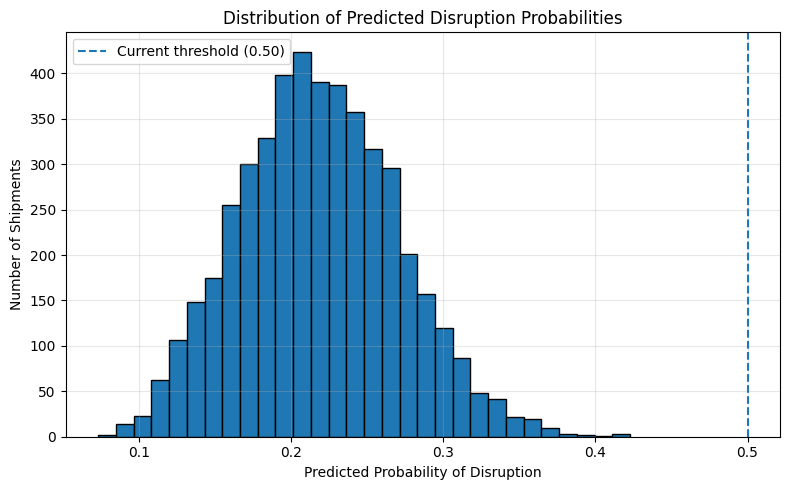

In [23]:
plt.figure(figsize=(8, 5))

plt.hist(test_prob, bins=30, edgecolor="black")

plt.axvline(
    0.50,
    linestyle="--",
    label="Current threshold (0.50)"
)

plt.xlabel("Predicted Probability of Disruption")
plt.ylabel("Number of Shipments")
plt.title("Distribution of Predicted Disruption Probabilities")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [25]:
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    brier_score_loss
)

print("Actual disruption rate:", round(y_test.mean(), 4))

print("Random baseline PR-AUC:", round(y_test.mean(), 4))

print("Model PR-AUC:",
      round(average_precision_score(y_test, test_prob), 4))

print("Model ROC-AUC:",
      round(roc_auc_score(y_test, test_prob), 4))

print("Brier Score:",
      round(brier_score_loss(y_test, test_prob), 4))

Actual disruption rate: 0.0738
Random baseline PR-AUC: 0.0738
Model PR-AUC: 0.0597
Model ROC-AUC: 0.4153
Brier Score: 0.094


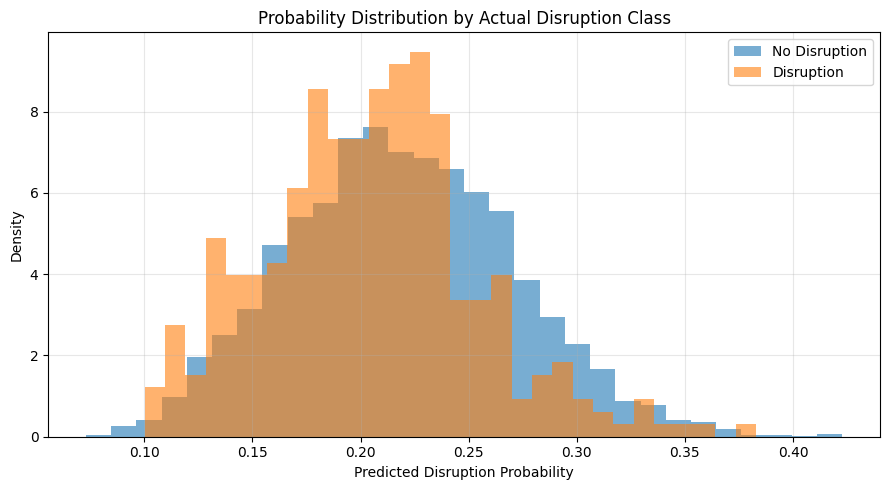

In [26]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(9, 5))

plt.hist(
    test_prob[np.array(y_test) == 0],
    bins=30,
    alpha=0.6,
    density=True,
    label="No Disruption"
)

plt.hist(
    test_prob[np.array(y_test) == 1],
    bins=30,
    alpha=0.6,
    density=True,
    label="Disruption"
)

plt.xlabel("Predicted Disruption Probability")
plt.ylabel("Density")
plt.title("Probability Distribution by Actual Disruption Class")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [24]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import average_precision_score, roc_auc_score

models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=400,
            max_depth=12,
            min_samples_split=10,
            min_samples_leaf=5,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", HistGradientBoostingClassifier(
            max_iter=200,
            learning_rate=0.05,
            max_leaf_nodes=15,
            random_state=42
        ))
    ])
}

comparison = []

for name, clf in models.items():

    clf.fit(X_train, y_train)

    probabilities = clf.predict_proba(X_val)[:, 1]

    comparison.append({
        "Model": name,
        "PR-AUC": average_precision_score(y_val, probabilities),
        "ROC-AUC": roc_auc_score(y_val, probabilities)
    })

comparison_df = pd.DataFrame(comparison).sort_values(
    "PR-AUC", ascending=False
)

print(comparison_df)

                 Model    PR-AUC   ROC-AUC
1        Random Forest  0.024403  0.529545
2    Gradient Boosting  0.024378  0.544190
0  Logistic Regression  0.023380  0.531343


In [8]:
# Intervention assumptions
intervention_costs = {
    "Road": 12000,
    "Rail": 15000,
    "Air": 20000,
    "Sea": 25000
}

disruption_loss = 50000

# Assumed percentage of disruption loss avoided by an intervention.
# 1.0 means 100% prevention; replace with evidence-based estimates
# when you have operational data.
intervention_effectiveness = 1.0

# Identify shipping method from one-hot columns
mode_columns = {
    "Road": "shipping_method_Road",
    "Rail": "shipping_method_Rail",
    "Air": "shipping_method_Air",
    "Sea": "shipping_method_Sea"
}

def get_shipping_mode(data):
    modes = pd.DataFrame({
        mode: data[col] for mode, col in mode_columns.items()
    })

    # Require exactly one selected shipping method per row
    if not (modes.sum(axis=1) == 1).all():
        raise ValueError(
            "Some rows do not have exactly one shipping method selected."
        )

    return modes.idxmax(axis=1)


def apply_intervention_policy(data, probabilities):
    results = data.copy()

    results["predicted_disruption_probability"] = probabilities
    results["shipping_mode"] = get_shipping_mode(results)

    results["intervention_cost"] = results["shipping_mode"].map(
        intervention_costs
    )

    # Expected loss avoided by intervening
    results["intervention_threshold"] = (
        results["intervention_cost"]
        / (disruption_loss * intervention_effectiveness)
    )

    results["intervene"] = (
        results["predicted_disruption_probability"]
        > results["intervention_threshold"]
    )

    return results


# Apply policy to held-out test observations
policy_results = apply_intervention_policy(test, test_prob)

print(policy_results[[
    "shipping_mode",
    "predicted_disruption_probability",
    "intervention_threshold",
    "intervene"
]].head(10))

      shipping_mode  predicted_disruption_probability  intervention_threshold  \
26350           Air                          0.153329                    0.40   
26351           Sea                          0.145353                    0.50   
26352           Air                          0.269146                    0.40   
26353          Road                          0.283107                    0.24   
26354           Air                          0.132574                    0.40   
26355           Sea                          0.210866                    0.50   
26356          Rail                          0.249330                    0.30   
26357          Rail                          0.092465                    0.30   
26358          Road                          0.231998                    0.24   
26359           Air                          0.170112                    0.40   

       intervene  
26350      False  
26351      False  
26352      False  
26353       True  
26354      Fa

In [9]:
# Actual next-week disruption outcome
policy_results["actual_disruption"] = y_test.values

# Baseline: never intervene
policy_results["baseline_cost"] = (
    policy_results["actual_disruption"] * disruption_loss
)

# Policy cost:
# - Pay intervention cost when intervening
# - Pay residual disruption loss if intervention does not prevent it
# - Pay full disruption loss when no intervention is made
policy_results["policy_cost"] = (
    policy_results["intervene"]
    * policy_results["intervention_cost"]
    +
    policy_results["actual_disruption"]
    * (
        1 - policy_results["intervene"]
        * intervention_effectiveness
    )
    * disruption_loss
)

baseline_total = policy_results["baseline_cost"].sum()
policy_total = policy_results["policy_cost"].sum()

savings = baseline_total - policy_total

print(f"Baseline cost: ${baseline_total:,.2f}")
print(f"Intervention policy cost: ${policy_total:,.2f}")
print(f"Total savings: ${savings:,.2f}")

if baseline_total > 0:
    print(f"Cost reduction: {savings / baseline_total:.2%}")

print(
    "Intervention rate:",
    f"{policy_results['intervene'].mean():.2%}"
)

Baseline cost: $17,350,000.00
Intervention policy cost: $22,570,000.00
Total savings: $-5,220,000.00
Cost reduction: -30.09%
Intervention rate: 11.51%


In [10]:
mode_results = (
    policy_results.groupby("shipping_mode")
    .agg(
        shipments=("actual_disruption", "size"),
        actual_disruptions=("actual_disruption", "sum"),
        interventions=("intervene", "sum"),
        baseline_cost=("baseline_cost", "sum"),
        policy_cost=("policy_cost", "sum")
    )
)

mode_results["savings"] = (
    mode_results["baseline_cost"] - mode_results["policy_cost"]
)

print(mode_results)

               shipments  actual_disruptions  interventions  baseline_cost  \
shipping_mode                                                                
Air                 1128                  84              2        4200000   
Rail                1504                 111             54        5550000   
Road                 940                  72            485        3600000   
Sea                 1128                  80              0        4000000   

               policy_cost    savings  
shipping_mode                          
Air              4240000.0   -40000.0  
Rail             6260000.0  -710000.0  
Road             8070000.0 -4470000.0  
Sea              4000000.0        0.0  


In [11]:
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    model,
    X_test,
    y_test,
    n_repeats=5,
    scoring="average_precision",
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance": importance.importances_mean
}).sort_values("importance", ascending=False)

print(importance_df.head(20))

                                    feature  importance
65             geopolitical_risk_score_lag1    0.000863
7                  weather_disruption_score    0.000743
17                   destination_population    0.000685
54                                 week_sin    0.000571
64            weather_disruption_score_lag2    0.000535
77   weather_disruption_score_rolling4_mean    0.000338
6                     commodity_price_index    0.000314
69                 trade_volume_tonnes_lag1    0.000287
60               port_congestion_index_lag2    0.000265
63            weather_disruption_score_lag1    0.000261
20          destination_port_capacity_index    0.000259
18               destination_gdp_per_capita    0.000242
9                   carbon_emissions_tonnes    0.000229
34           geopolitical_max_duration_days    0.000214
40            event_count_Maritime Conflict    0.000202
39           event_count_Export Restriction    0.000152
79                       congestion_x_delay    0

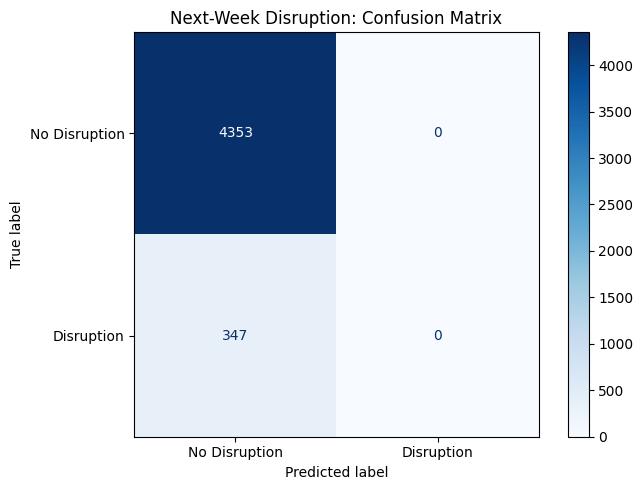

In [12]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    precision_recall_curve,
    auc
)

# Classification threshold
threshold = 0.50
test_pred = (test_prob >= threshold).astype(int)

cm = confusion_matrix(y_test, test_pred)

fig, ax = plt.subplots(figsize=(7, 5))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Disruption", "Disruption"]
)
disp.plot(cmap="Blues", ax=ax, values_format="d")

ax.set_title("Next-Week Disruption: Confusion Matrix")
plt.tight_layout()
plt.show()

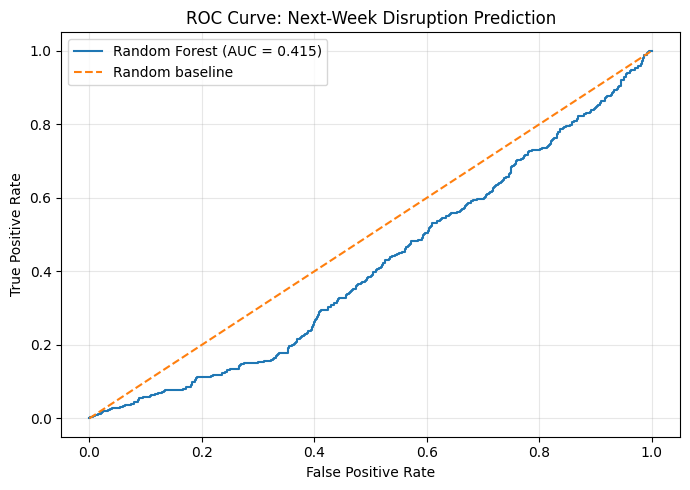

In [13]:
fpr, tpr, thresholds = roc_curve(y_test, test_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Random Forest (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve: Next-Week Disruption Prediction")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

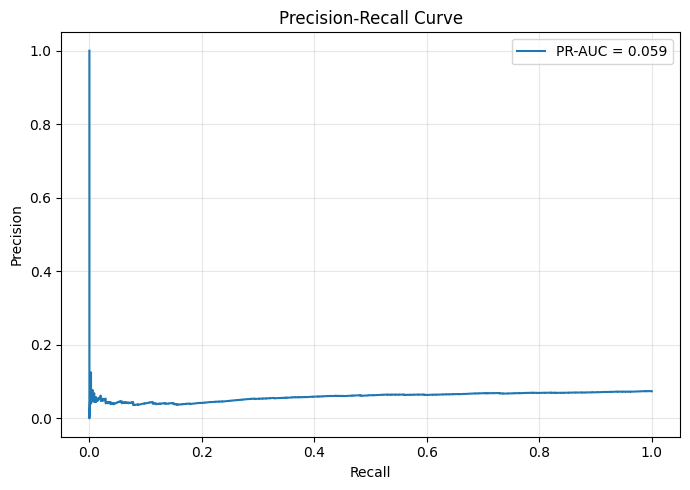

In [14]:
precision, recall, pr_thresholds = precision_recall_curve(
    y_test, test_prob
)

pr_auc = auc(recall, precision)

plt.figure(figsize=(7, 5))
plt.plot(recall, precision, label=f"PR-AUC = {pr_auc:.3f}")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

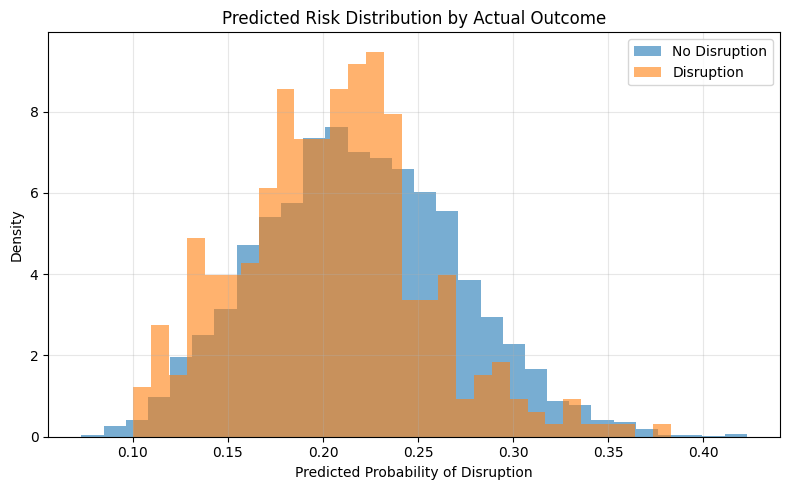

In [15]:
plt.figure(figsize=(8, 5))

plt.hist(
    test_prob[np.array(y_test) == 0],
    bins=30,
    alpha=0.6,
    label="No Disruption",
    density=True
)

plt.hist(
    test_prob[np.array(y_test) == 1],
    bins=30,
    alpha=0.6,
    label="Disruption",
    density=True
)

plt.xlabel("Predicted Probability of Disruption")
plt.ylabel("Density")
plt.title("Predicted Risk Distribution by Actual Outcome")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

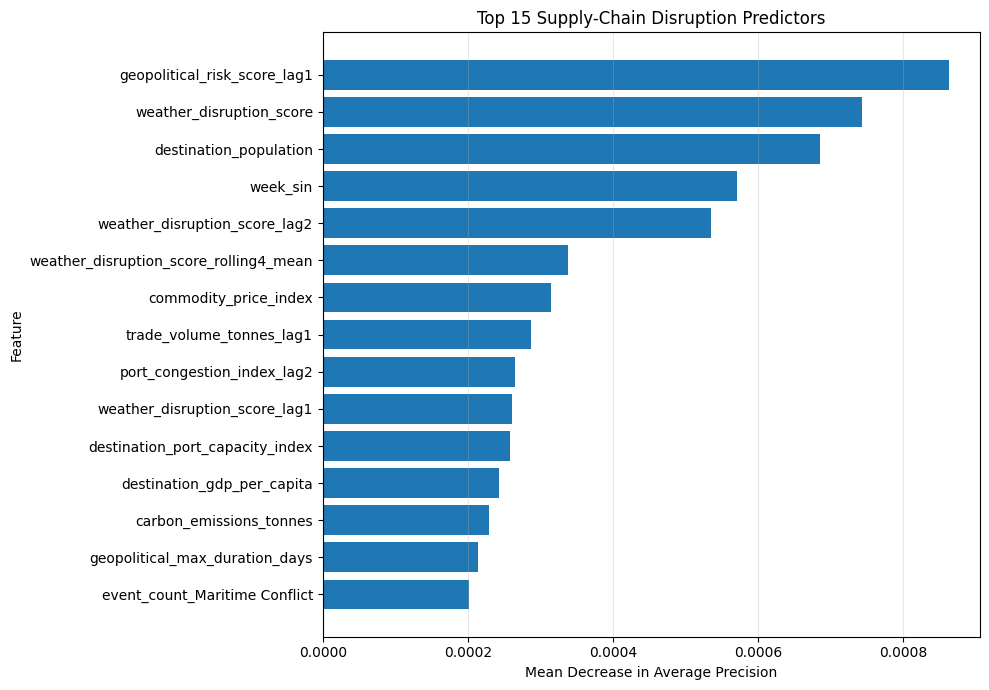

In [16]:
top_features = importance_df.head(15).sort_values(
    "importance", ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["feature"],
    top_features["importance"]
)

plt.xlabel("Mean Decrease in Average Precision")
plt.ylabel("Feature")
plt.title("Top 15 Supply-Chain Disruption Predictors")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

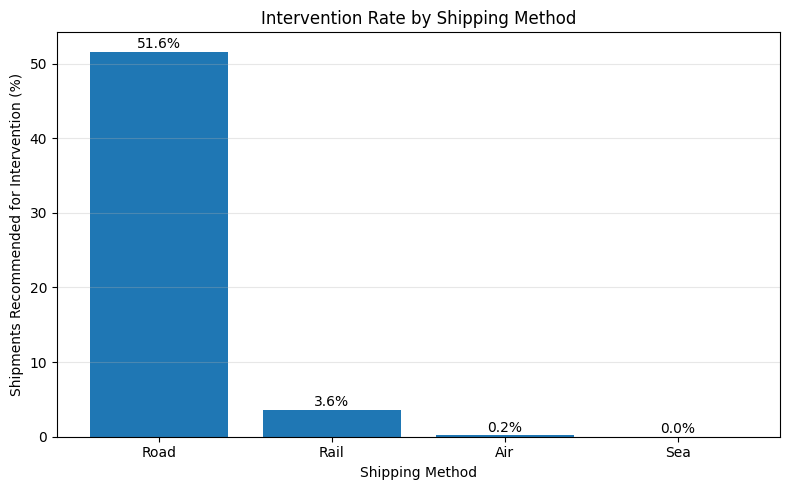

In [17]:
intervention_rates = (
    policy_results.groupby("shipping_mode")["intervene"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

plt.bar(
    intervention_rates.index,
    intervention_rates.values * 100
)

plt.ylabel("Shipments Recommended for Intervention (%)")
plt.xlabel("Shipping Method")
plt.title("Intervention Rate by Shipping Method")

for i, value in enumerate(intervention_rates.values):
    plt.text(i, value * 100 + 0.5, f"{value:.1%}", ha="center")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

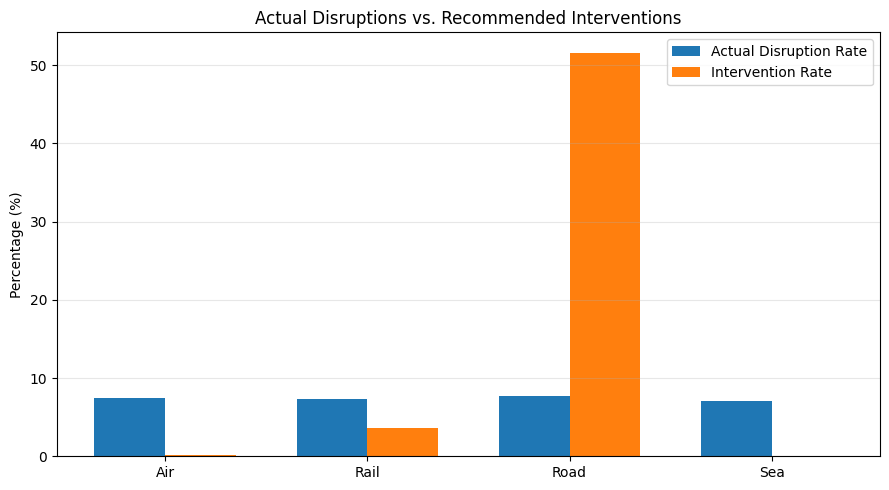

In [18]:
comparison = (
    policy_results.groupby("shipping_mode")
    .agg(
        actual_disruption_rate=("actual_disruption", "mean"),
        intervention_rate=("intervene", "mean")
    )
)

x = np.arange(len(comparison))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width/2,
    comparison["actual_disruption_rate"] * 100,
    width,
    label="Actual Disruption Rate"
)

plt.bar(
    x + width/2,
    comparison["intervention_rate"] * 100,
    width,
    label="Intervention Rate"
)

plt.xticks(x, comparison.index)
plt.ylabel("Percentage (%)")
plt.title("Actual Disruptions vs. Recommended Interventions")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

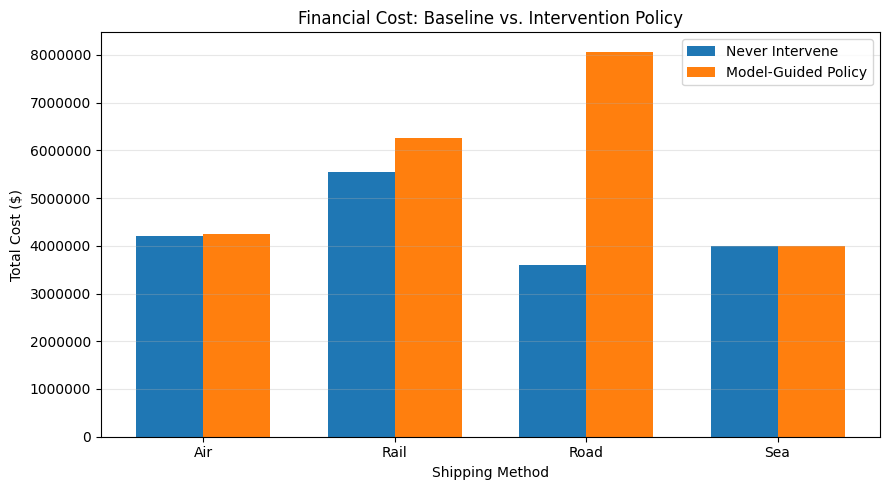

In [19]:
cost_comparison = mode_results[
    ["baseline_cost", "policy_cost"]
]

x = np.arange(len(cost_comparison))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width/2,
    cost_comparison["baseline_cost"],
    width,
    label="Never Intervene"
)

plt.bar(
    x + width/2,
    cost_comparison["policy_cost"],
    width,
    label="Model-Guided Policy"
)

plt.xticks(x, cost_comparison.index)
plt.ylabel("Total Cost ($)")
plt.xlabel("Shipping Method")
plt.title("Financial Cost: Baseline vs. Intervention Policy")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()

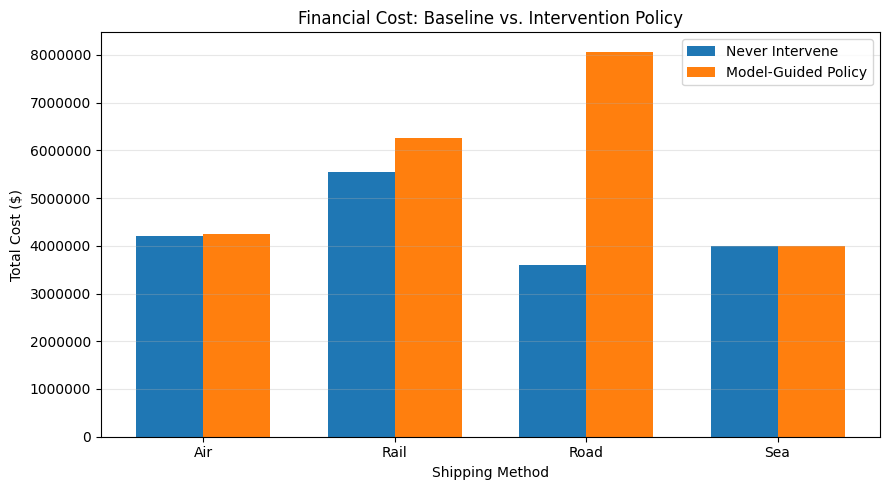

In [20]:
cost_comparison = mode_results[
    ["baseline_cost", "policy_cost"]
]

x = np.arange(len(cost_comparison))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width/2,
    cost_comparison["baseline_cost"],
    width,
    label="Never Intervene"
)

plt.bar(
    x + width/2,
    cost_comparison["policy_cost"],
    width,
    label="Model-Guided Policy"
)

plt.xticks(x, cost_comparison.index)
plt.ylabel("Total Cost ($)")
plt.xlabel("Shipping Method")
plt.title("Financial Cost: Baseline vs. Intervention Policy")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()